# Microchannel detection in a mother machine stack — step by step

This notebook explains, with a figure for every step, how `detectar_canales` (in `kimogramas.py`) finds the
microchannels in a brightfield time-lapse. **It is classical image processing — no neural network.**
It only needs an *aligned* stack, because it relies on the fact that the chip is rigid while the cells move.

The idea in one paragraph: the chip looks like a comb. Averaging the whole movie keeps the comb sharp and washes
the cells out. Because the comb is periodic, an autocorrelation gives the channel period; the channel axes are the
minima of the horizontal intensity profile; the closed end and the exit of each channel are where the walls start and
stop; and finally we use the fact that all closed ends (and all exits) must lie on a straight line to repair any
channel where a cell fooled the detector.

| Step | What it does | Main tool |
|---|---|---|
| 0 | Load the aligned brightfield stack | `tifffile` |
| 1 | Median image over time (chip stays, cells vanish) | `np.median` |
| 2 | Find the band of the image that contains the channels | wall energy + autocorrelation per row |
| 3 | Channel period and channel positions | autocorrelation + `find_peaks` |
| 4 | Channels cut by the image border | extrapolate the comb |
| 5 | Axis of every channel (handles small tilts) | linear fit x = a + b·y |
| 6 | Closed end and exit of every channel | wall energy along the axis |
| 7 | Rigid-chip correction | robust line fit of ends and exits |
| 8 | Result, check against the pipeline, straightened channels and kymograph | — |
| 9 | Hard-coded parameters and what to change for another organism / chip | — |

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter, gaussian_filter1d, map_coordinates
from scipy.signal import find_peaks

# ---- Paths: edit these -------------------------------------------------------------------
BASE = Path(os.environ.get('MM_BASE', '/Users/javiermolina/Desktop/TESIS CNB/Becas y matriculas de doctorado/'
                                       'Estancia Exeter/Experimentos Microfluidica/2026'))
STACK = BASE / 'October/2/Stacks/01-02102026-BF.tif'                      # aligned brightfield stack (T, Y, X)
REFERENCE_CSV = BASE / 'October/2/Stacks/Kimogramas/01-02102026_canales.csv'   # output of the pipeline, to compare
PIPELINE_SCRIPTS = BASE / 'mother-machine-pipeline/scripts'                    # where kimogramas.py lives
# ------------------------------------------------------------------------------------------

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11, 'axes.labelsize': 10, 'font.size': 9})
BLUE, ORANGE, GREEN, RED, GREY = '#2a6fdb', '#e8871e', '#2a9d6f', '#d6453d', '#8a8f98'

## Step 0 — Load the stack

The input is an **aligned** brightfield stack of shape `(T, Y, X)`. Alignment matters: if the frames drifted, the median
image of step 1 would blur the chip as well. Here the channels run roughly vertically, the closed end of each channel
is at the top and the exit (into the feeding trench) at the bottom.

stack shape (T, Y, X): (75, 700, 1000) uint8


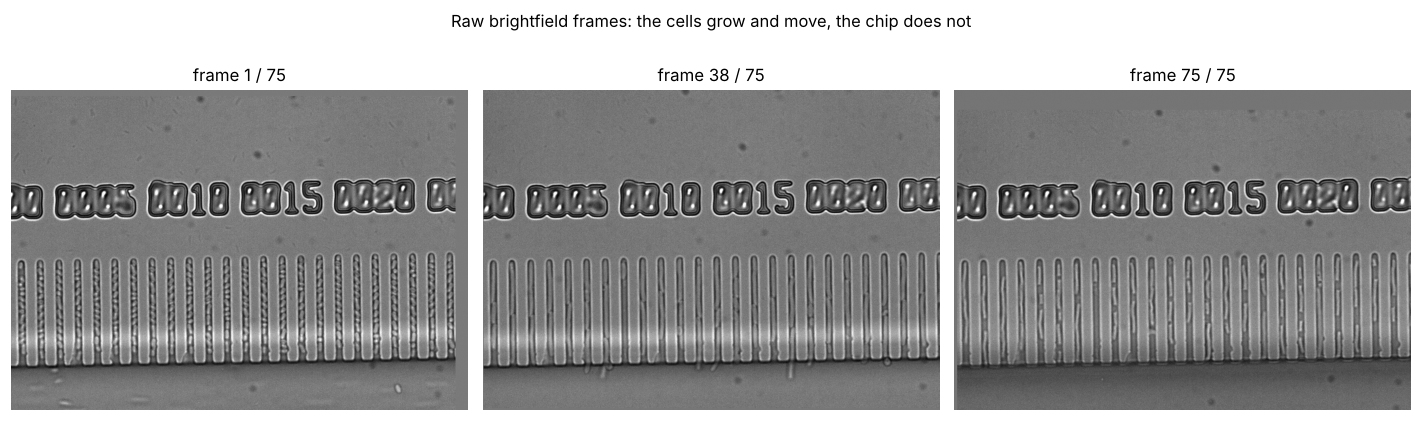

In [2]:
with tifffile.TiffFile(STACK) as tif:
    bf = tif.asarray()
print('stack shape (T, Y, X):', bf.shape, bf.dtype)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, t in zip(ax, [0, len(bf) // 2, len(bf) - 1]):
    a.imshow(bf[t], cmap='gray'); a.set_title(f'frame {t + 1} / {len(bf)}'); a.axis('off')
fig.suptitle('Raw brightfield frames: the cells grow and move, the chip does not')
plt.tight_layout(); plt.show()

## Step 1 — Median over time

The median of all frames keeps whatever is **static** (the PDMS walls of the chip) and removes whatever **moves**
(cells growing, dividing, leaving the channel). A pixel-wise standard deviation shows the complementary picture:
it is high only where cells are. A light Gaussian blur (σ = 1 px) removes pixel noise before taking derivatives.

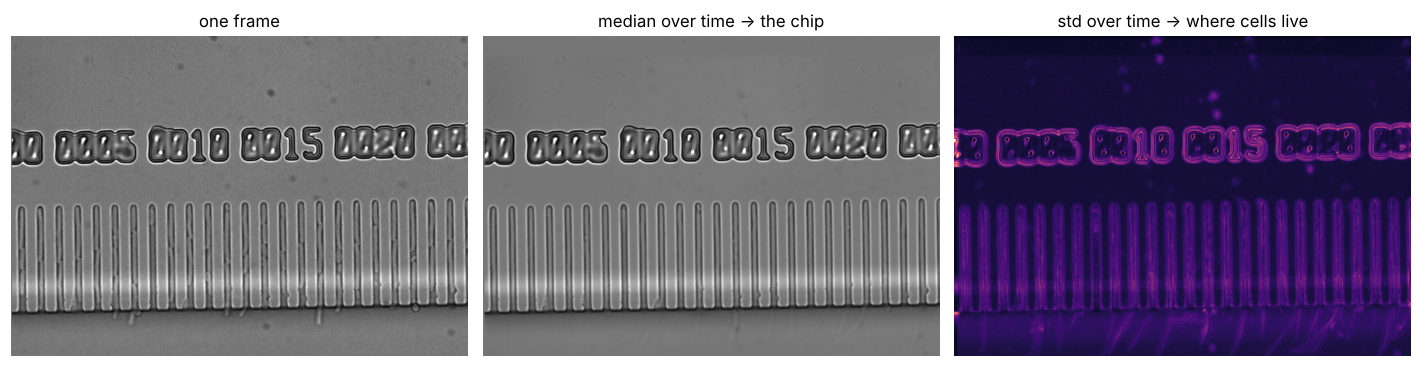

In [3]:
media = np.median(bf, axis=0)
sd_t = bf.astype(float).std(axis=0)
M = gaussian_filter(media.astype(float), 1)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
ax[0].imshow(bf[len(bf) // 2], cmap='gray'); ax[0].set_title('one frame')
ax[1].imshow(media, cmap='gray'); ax[1].set_title('median over time → the chip')
ax[2].imshow(sd_t, cmap='magma'); ax[2].set_title('std over time → where cells live')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## Step 2 — Where is the band of channels?

The image also contains numbers, the feeding trench and empty chip. We want the rows where the *comb* is.
Two cheap descriptors, computed row by row:

* **Wall energy** — `gx = |∂M/∂x|`, averaged along x. Channel rows are full of vertical edges (the walls).
* **Periodicity** — the autocorrelation of the horizontal intensity profile of that row (±3 rows), evaluated at its best lag between
  20 and 80 px. A comb gives a high value (close to 1); a uniform region or a number does not.

A row is *channel* if `periodicity > 0.4` **and** `energy > 30 % of max`. The longest contiguous run of such rows is the band.

channel band: rows 364 – 597  (233 px tall)


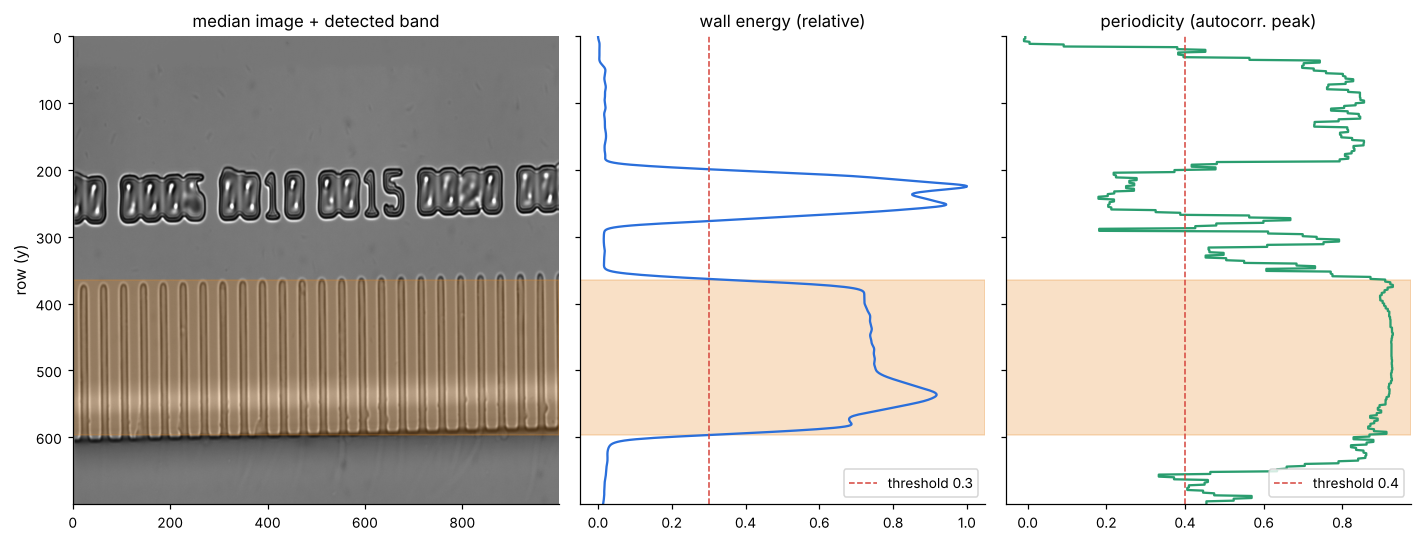

In [4]:
PERIODO_MIN, PERIODO_MAX = 20, 80

def autocorr_periodo(perfil, lag_min=PERIODO_MIN, lag_max=PERIODO_MAX):
    p = perfil - perfil.mean()
    ac = np.correlate(p, p, mode='full')[len(p) - 1:]
    ac = ac / ac[0]
    lags = np.arange(lag_min, min(lag_max, len(ac) - 1))
    k = lags[np.argmax(ac[lags])]
    return int(k), float(ac[k])

gx = np.abs(np.diff(M, axis=1))
energia = gaussian_filter1d(gx.mean(1), 3)

periodicidad = np.zeros(M.shape[0])
for y in range(0, M.shape[0], 4):
    fila = M[max(0, y - 3):y + 4].mean(0)
    periodicidad[y:y + 4] = autocorr_periodo(fila)[1]

UMBRAL_PERIOD, UMBRAL_ENERGIA = 0.4, 0.3
es_canal = (periodicidad > UMBRAL_PERIOD) & (energia > UMBRAL_ENERGIA * energia.max())

# longest contiguous run
mejor, ini = (0, 0, 0), None
for y, v in enumerate(np.r_[es_canal, False]):
    if v and ini is None:
        ini = y
    if not v and ini is not None:
        if y - ini > mejor[0]:
            mejor = (y - ini, ini, y)
        ini = None
_, y0, y1 = mejor
print(f'channel band: rows {y0} – {y1}  ({y1 - y0} px tall)')

fig, ax = plt.subplots(1, 3, figsize=(13, 5), gridspec_kw={'width_ratios': [1.2, 1, 1]}, sharey=True)
ax[0].imshow(media, cmap='gray', aspect='auto')
ax[0].axhspan(y0, y1, color=ORANGE, alpha=0.25); ax[0].set_title('median image + detected band')
ys_all = np.arange(M.shape[0])
ax[1].plot(energia / energia.max(), ys_all, color=BLUE)
ax[1].axvline(UMBRAL_ENERGIA, color=RED, ls='--', lw=1, label=f'threshold {UMBRAL_ENERGIA}')
ax[1].set_title('wall energy (relative)'); ax[1].legend(loc='lower right')
ax[2].plot(periodicidad, ys_all, color=GREEN)
ax[2].axvline(UMBRAL_PERIOD, color=RED, ls='--', lw=1, label=f'threshold {UMBRAL_PERIOD}')
ax[2].set_title('periodicity (autocorr. peak)'); ax[2].legend(loc='lower right')
for a in ax[1:]:
    a.axhspan(y0, y1, color=ORANGE, alpha=0.25)
ax[0].set_ylabel('row (y)')
plt.tight_layout(); plt.show()

## Step 3 — Channel period and channel positions

We average the horizontal profile over the **central half** of the band (the part least affected by the closed ends and by the exit).
In that profile each channel is a dip (channels are darker than the walls in this chip).

1. **Period.** The autocorrelation of the profile peaks at the channel spacing. We look for the highest peak with lag 20–80 px.
2. **Positions.** Smooth the profile with σ = period/7 and take its minima, at least 0.6 × period apart.
3. **Prominence filter.** Keep only minima with prominence > 30 % of the *typical* prominence (median of the larger half), which removes
   dips caused by dirt or a stray cell.

period = 41 px  (autocorrelation peak = 0.93)
24 candidate minima → 24 kept


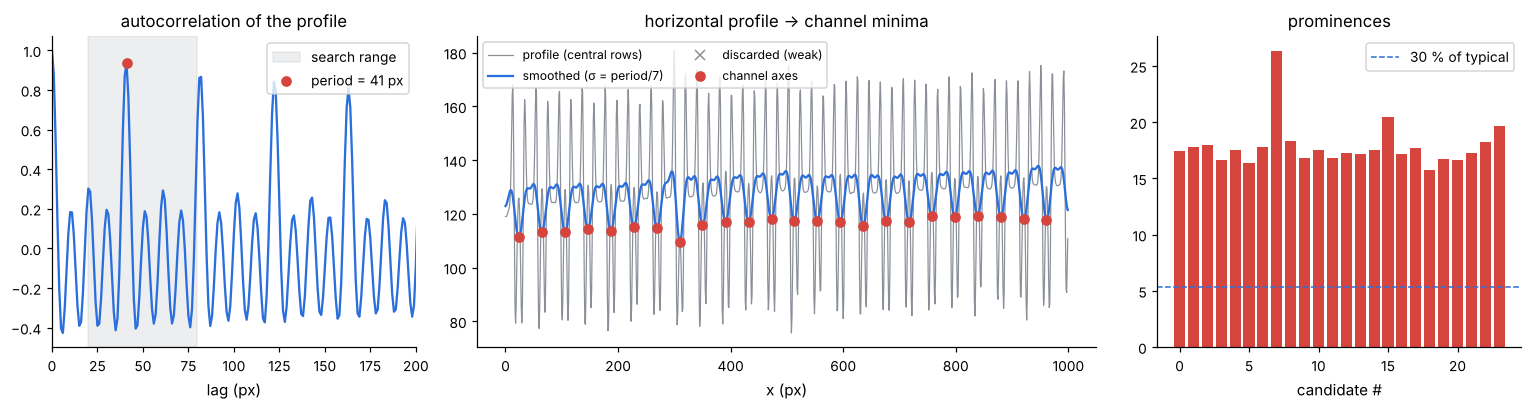

In [5]:
centro = slice(y0 + (y1 - y0) // 4, y1 - (y1 - y0) // 4)
perfil = M[centro].mean(0)
periodo, ac_pico = autocorr_periodo(perfil)
print(f'period = {periodo} px  (autocorrelation peak = {ac_pico:.2f})')

p = perfil - perfil.mean()
ac = np.correlate(p, p, mode='full')[len(p) - 1:]; ac /= ac[0]

suave = gaussian_filter1d(perfil, periodo / 7)
minimos_all, props = find_peaks(-suave, distance=int(0.6 * periodo), prominence=0)
prom = props['prominences']
ref = np.median(np.sort(prom)[-max(3, len(prom) // 2):])
keep = prom > 0.3 * ref
minimos = minimos_all[keep]
print(f'{len(minimos_all)} candidate minima → {keep.sum()} kept')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={'width_ratios': [1, 1.7, 1]})
ax[0].plot(np.arange(len(ac)), ac, color=BLUE)
ax[0].axvspan(PERIODO_MIN, PERIODO_MAX, color=GREY, alpha=0.15, label='search range')
ax[0].plot(periodo, ac[periodo], 'o', color=RED, label=f'period = {periodo} px')
ax[0].set_xlim(0, 200); ax[0].set_xlabel('lag (px)'); ax[0].set_title('autocorrelation of the profile'); ax[0].legend()

ax[1].plot(perfil, color=GREY, lw=0.8, label='profile (central rows)')
ax[1].plot(suave, color=BLUE, label='smoothed (σ = period/7)')
ax[1].plot(minimos_all[~keep], suave[minimos_all[~keep]], 'x', color=GREY, label='discarded (weak)')
ax[1].plot(minimos, suave[minimos], 'o', color=RED, label='channel axes')
ax[1].set_xlabel('x (px)'); ax[1].set_title('horizontal profile → channel minima'); ax[1].legend(ncol=2, fontsize=8)

ax[2].bar(np.arange(len(prom)), prom, color=[RED if k else GREY for k in keep])
ax[2].axhline(0.3 * ref, color=BLUE, ls='--', lw=1, label='30 % of typical')
ax[2].set_xlabel('candidate #'); ax[2].set_title('prominences'); ax[2].legend()
plt.tight_layout(); plt.show()

## Step 4 — Channels cut by the image border

A channel at the edge of the field of view may be only partly visible and have no clean minimum. We **extend the comb** one period to
each side and accept the extra channel only if (i) the predicted axis fits inside the image, (ii) the profile there is darker than the
median, and (iii) the local contrast (standard deviation of the profile within ± period/2) is at least half of the typical channel's.

predicted x =   -17.0  → candidate None  accepted: False
predicted x =  1002.0  → candidate 1002  accepted: False
24 detected + 0 extrapolated = 24 channels


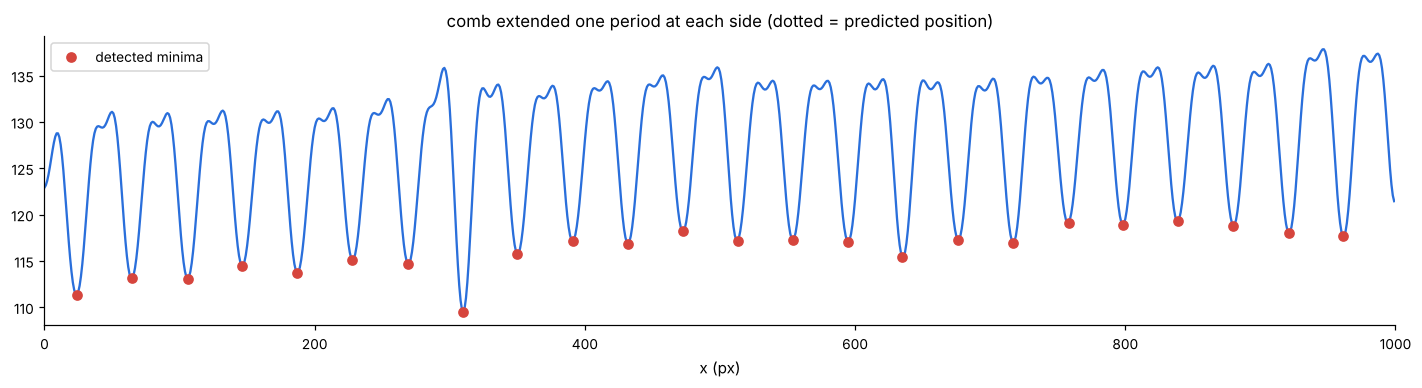

In [6]:
margen = periodo // 2
def contraste(x):
    return float(np.std(perfil[max(0, x - margen):min(len(perfil), x + margen)]))
contraste_tipico = np.median([contraste(x) for x in minimos])

extra, intentos = [], []
for x_pred in (minimos.min() - periodo, minimos.max() + periodo):
    lo, hi = max(int(x_pred - periodo // 4), 0), min(int(x_pred + periodo // 4) + 1, M.shape[1])
    if hi - lo < 3:
        intentos.append((x_pred, None, False)); continue
    x = lo + int(np.argmin(suave[lo:hi]))
    if x in (lo, hi - 1):
        x = int(round(x_pred))
    ok = (2 <= x <= M.shape[1] - 2 and suave[x] < np.median(suave) and contraste(x) > 0.5 * contraste_tipico)
    intentos.append((x_pred, x, ok))
    if ok:
        extra.append(x)
minimos_before = minimos.copy()
minimos = np.sort(np.r_[minimos, extra]).astype(int)
minimos = minimos[(minimos >= 2) & (minimos <= M.shape[1] - 2)]
for xp, x, ok in intentos:
    print(f'predicted x = {xp:7.1f}  → candidate {x}  accepted: {ok}' + (f'  (contrast {contraste(x):.2f} vs typical {contraste_tipico:.2f})' if x is not None and 0 <= x < len(perfil) else ''))
print(f'{len(minimos_before)} detected + {len(extra)} extrapolated = {len(minimos)} channels')

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(suave, color=BLUE)
ax.plot(minimos_before, suave[minimos_before], 'o', color=RED, label='detected minima')
if len(extra):
    ax.plot(extra, suave[extra], 's', color=ORANGE, ms=8, label='extrapolated (edge channels)')
for xp, x, ok in intentos:
    ax.axvline(xp, color=GREY, ls=':', lw=1)
ax.set_xlim(0, len(suave)); ax.set_xlabel('x (px)'); ax.set_title('comb extended one period at each side (dotted = predicted position)')
ax.legend(); plt.tight_layout(); plt.show()

## Step 5 — Axis of every channel

Channels are never perfectly vertical. For every channel we look, at heights `y = y0+5, y0+13, …` (every 8 px), for the
minimum of the horizontal profile (±3 rows, smoothed) within ± period/3 of the channel's x. Those points
`(x_k, y_k)` are fitted with a straight line **x = a + b·y**. If the slope is absurd (|b| > 0.1) the channel is forced to be vertical.

slopes b: median +0.0146, range [-0.0021, +0.0187]   (+0.84° median tilt)


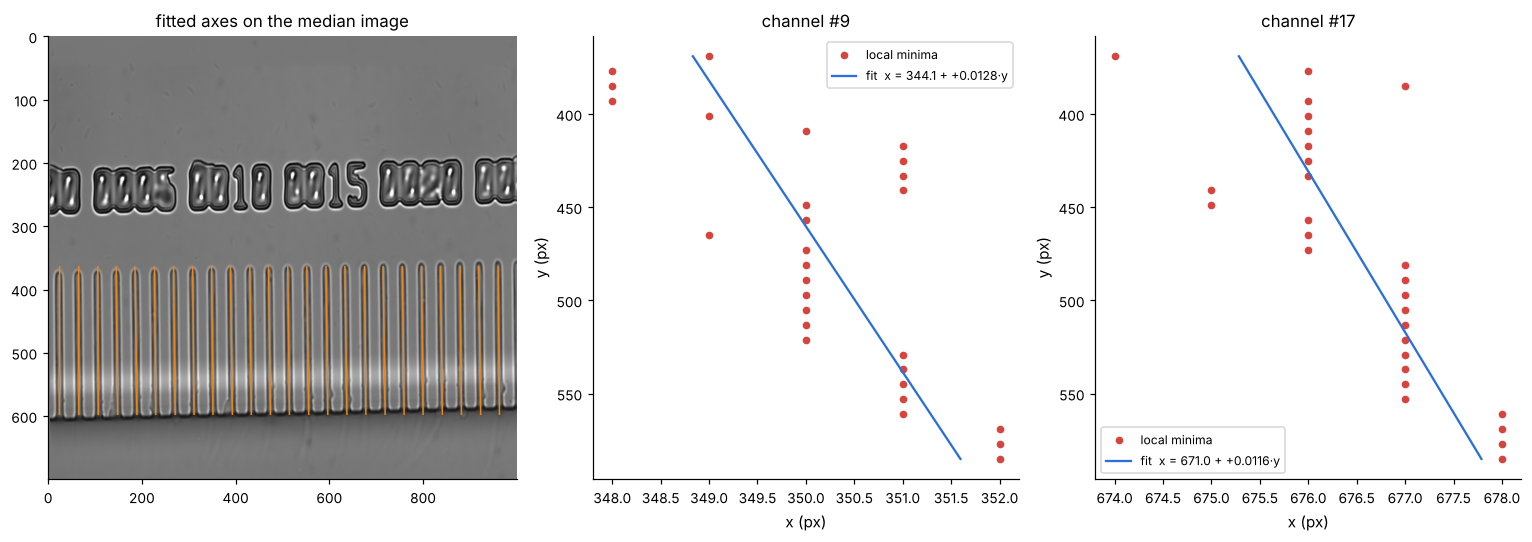

In [7]:
ys = np.arange(y0 + 5, y1 - 5, 8)
ejes = []   # (xc, a, b, xs)
for xc in minimos:
    xs = []
    for y in ys:
        f = gaussian_filter1d(M[y - 3:y + 4].mean(0), periodo / 7)
        lo, hi = max(int(xc - periodo // 3), 0), min(int(xc + periodo // 3) + 1, M.shape[1])
        xs.append(lo + np.argmin(f[lo:hi]))
    b, a = np.polyfit(ys, xs, 1)
    if abs(b) > 0.1:
        a, b = float(np.median(xs)), 0.0
    ejes.append((xc, a, b, np.array(xs)))
slopes = np.array([e[2] for e in ejes])
print(f'slopes b: median {np.median(slopes):+.4f}, range [{slopes.min():+.4f}, {slopes.max():+.4f}]   '
      f'({np.degrees(np.arctan(np.median(slopes))):+.2f}° median tilt)')

fig, ax = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ax[0].imshow(media, cmap='gray', aspect='auto')
for xc, a, b, xs in ejes:
    ax[0].plot(a + b * np.array([y0, y1]), [y0, y1], color=ORANGE, lw=1)
ax[0].set_title('fitted axes on the median image')
for a_, idx in zip(ax[1:], [len(ejes) // 3, 2 * len(ejes) // 3]):
    xc, a, b, xs = ejes[idx]
    a_.plot(xs, ys, 'o', color=RED, ms=4, label='local minima')
    a_.plot(a + b * ys, ys, color=BLUE, label=f'fit  x = {a:.1f} + {b:+.4f}·y')
    a_.invert_yaxis(); a_.set_xlabel('x (px)'); a_.set_ylabel('y (px)'); a_.set_title(f'channel #{idx + 1}'); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 6 — Closed end and exit of every channel

Around each axis (± period/2) we average the wall energy `gx` along x, giving a vertical profile `e(y)`. Inside the channel
the walls produce high energy; above the closed end and below the exit there is none. We take
`level = 0.5 × median(e) inside the band`, and call the first / last row above it (within ±40 px of the band) the **closed end** / **exit**.

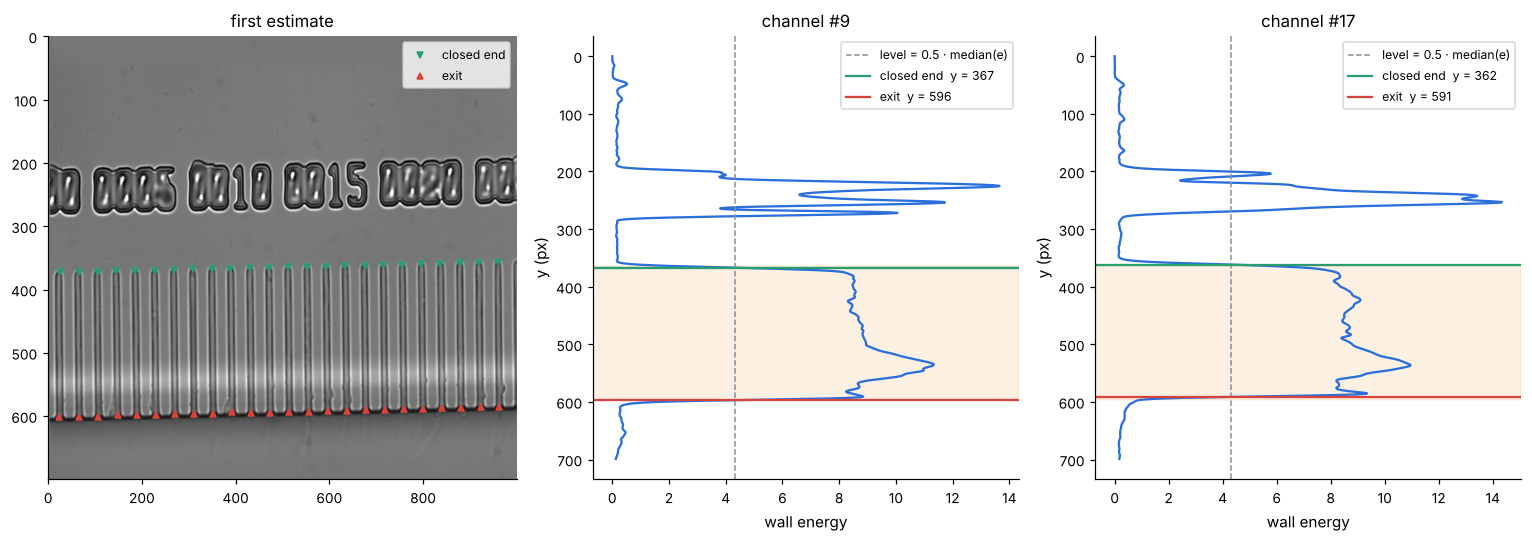

In [8]:
filas = []
perfiles_e = []
for xc, a, b, xs in ejes:
    lo, hi = max(int(xc - margen), 0), min(int(xc + margen), gx.shape[1])
    e = gaussian_filter1d(gx[:, lo:hi].mean(1), 2)
    nivel = 0.5 * np.median(e[y0:y1])
    dentro = np.where(e > nivel)[0]
    dentro = dentro[(dentro > y0 - 40) & (dentro < y1 + 40)]
    ys_c, ye_c = (dentro.min(), dentro.max()) if len(dentro) else (y0, y1)
    filas.append(dict(x_sup=a + b * ys_c, y_sup=float(ys_c), x_inf=a + b * ye_c, y_inf=float(ye_c),
                      al_borde=bool(xc < margen or xc > M.shape[1] - margen)))
    perfiles_e.append((e, nivel))
canales0 = pd.DataFrame(filas)       # before the rigid-chip correction

fig, ax = plt.subplots(1, 3, figsize=(14, 5), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ax[0].imshow(media, cmap='gray', aspect='auto')
ax[0].plot(canales0.x_sup, canales0.y_sup, 'v', color=GREEN, ms=4, label='closed end')
ax[0].plot(canales0.x_inf, canales0.y_inf, '^', color=RED, ms=4, label='exit')
ax[0].set_title('first estimate'); ax[0].legend(loc='upper right', fontsize=8)
for a_, idx in zip(ax[1:], [len(ejes) // 3, 2 * len(ejes) // 3]):
    e, nivel = perfiles_e[idx]
    a_.plot(e, np.arange(len(e)), color=BLUE)
    a_.axvline(nivel, color=GREY, ls='--', lw=1, label='level = 0.5 · median(e)')
    a_.axhline(canales0.y_sup[idx], color=GREEN, label=f'closed end  y = {canales0.y_sup[idx]:.0f}')
    a_.axhline(canales0.y_inf[idx], color=RED, label=f'exit  y = {canales0.y_inf[idx]:.0f}')
    a_.axhspan(y0, y1, color=ORANGE, alpha=0.12)
    a_.invert_yaxis(); a_.set_xlabel('wall energy'); a_.set_ylabel('y (px)'); a_.set_title(f'channel #{idx + 1}'); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 7 — Use the rigidity of the chip

All closed ends sit on one straight line (the chip was moulded in one piece) and so do all exits. We exploit this:
fit `y = slope·x + intercept` to the ends, **robustly** (three iterations, each time keeping only points whose residual is below
`max(3 px, 2.5 × median |residual|)`), and any channel whose residual is above 6 px is moved onto the line. This repairs
cases such as a dark cell that tricked the exit detector. After moving an end, its x is recomputed along the channel axis.

channels corrected at the closed end: 0   at the exit: 0


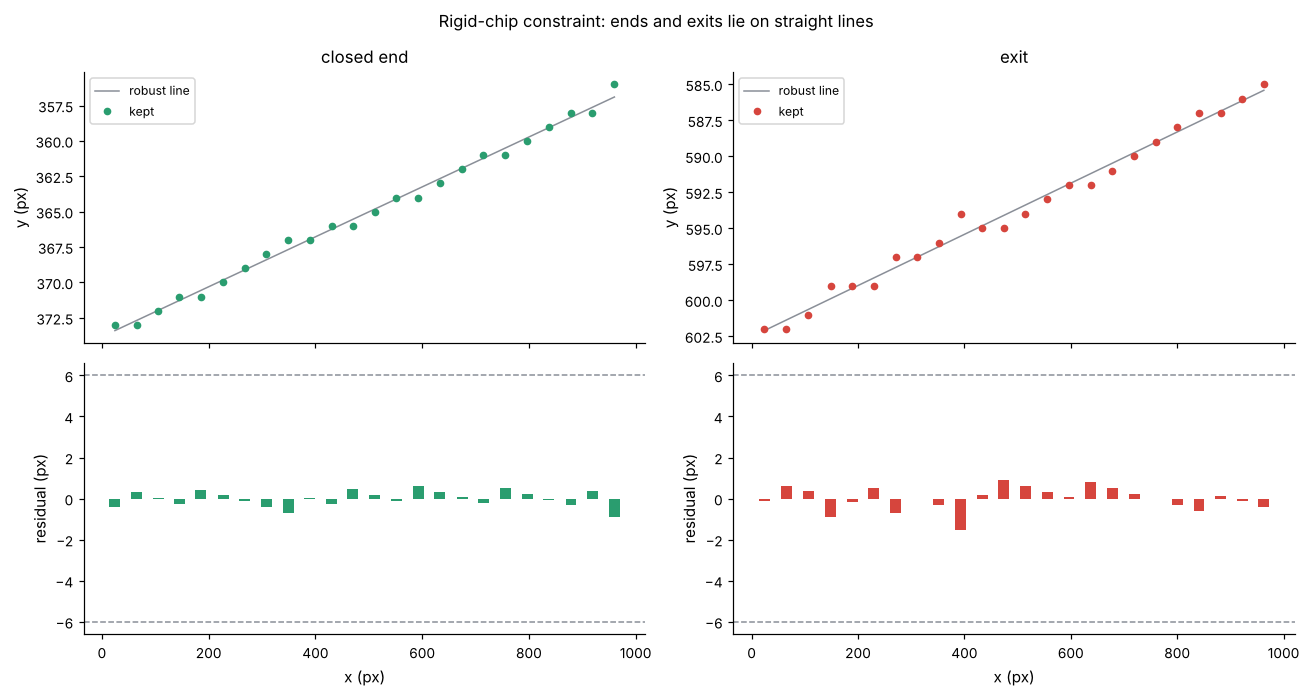

In [9]:
canales = canales0.copy()
ajustes = {}
for xcol, ycol in (('x_sup', 'y_sup'), ('x_inf', 'y_inf')):
    x, y = canales[xcol].to_numpy(), canales[ycol].to_numpy()
    ok = np.ones(len(x), bool)
    for _ in range(3):
        pend, ord_ = np.polyfit(x[ok], y[ok], 1) if ok.sum() >= 3 else (0.0, np.median(y))
        res = y - (pend * x + ord_)
        ok = np.abs(res) <= max(3.0, 2.5 * np.median(np.abs(res[ok])))
    malos = np.abs(res) > 6
    canales.loc[malos, ycol] = pend * x[malos] + ord_
    canales['corregido_' + ycol[2:]] = malos
    ajustes[ycol] = (pend, ord_, res, malos, x, y)

for i, f in enumerate(filas):
    b = (f['x_inf'] - f['x_sup']) / (f['y_inf'] - f['y_sup']) if f['y_inf'] != f['y_sup'] else 0.0
    canales.loc[i, 'x_sup'] = f['x_sup'] + b * (canales.loc[i, 'y_sup'] - f['y_sup'])
    canales.loc[i, 'x_inf'] = f['x_sup'] + b * (canales.loc[i, 'y_inf'] - f['y_sup'])
canales.insert(0, 'canal', np.arange(1, len(canales) + 1))
canales['longitud_px'] = np.hypot(canales.x_inf - canales.x_sup, canales.y_inf - canales.y_sup)
print('channels corrected at the closed end:', int(canales.corregido_sup.sum()),
      '  at the exit:', int(canales.corregido_inf.sum()))

fig, ax = plt.subplots(2, 2, figsize=(12, 6.4), sharex='col')
for j, (ycol, nombre, col) in enumerate((('y_sup', 'closed end', GREEN), ('y_inf', 'exit', RED))):
    pend, ord_, res, malos, x, y = ajustes[ycol]
    xx = np.linspace(x.min(), x.max(), 10)
    ax[0, j].plot(xx, pend * xx + ord_, color=GREY, lw=1, label='robust line')
    ax[0, j].plot(x[~malos], y[~malos], 'o', color=col, ms=4, label='kept')
    if malos.any():
        ax[0, j].plot(x[malos], y[malos], 'X', color=ORANGE, ms=9, label='corrected')
    ax[0, j].invert_yaxis(); ax[0, j].set_ylabel('y (px)'); ax[0, j].set_title(nombre); ax[0, j].legend(fontsize=8)
    ax[1, j].bar(x, res, width=periodo * 0.5, color=[ORANGE if m else col for m in malos])
    ax[1, j].axhline(6, color=GREY, ls='--', lw=1); ax[1, j].axhline(-6, color=GREY, ls='--', lw=1)
    ax[1, j].set_xlabel('x (px)'); ax[1, j].set_ylabel('residual (px)')
plt.suptitle('Rigid-chip constraint: ends and exits lie on straight lines'); plt.tight_layout(); plt.show()

## Step 8 — Final result

Channels are numbered **left to right**. For every channel we now have the axis, the closed end `(x_sup, y_sup)` and
the exit `(x_inf, y_inf)`. Below: the overlay on the median image and on a real frame (cells are visible here).

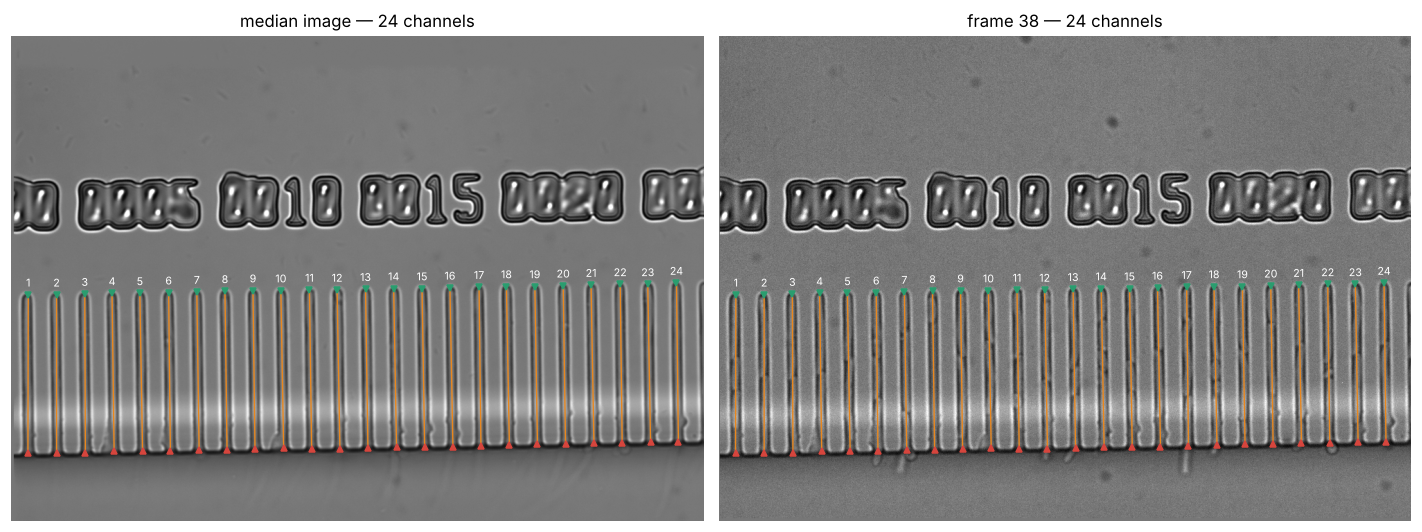

,canal,x_sup,y_sup,x_inf,y_inf,al_borde,corregido_sup,corregido_inf,longitud_px
0,1,24.43,373.0,23.95,602.0,False,False,False,229.00
1,2,65.26,373.0,65.31,602.0,False,False,False,229.00
2,3,106.00,372.0,106.86,601.0,False,False,False,229.00
3,4,145.36,371.0,148.35,599.0,False,False,False,228.02
4,5,185.49,371.0,189.43,599.0,False,False,False,228.03
5,6,227.09,370.0,229.57,599.0,False,False,False,229.01
6,7,267.74,369.0,271.07,597.0,False,False,False,228.02
7,8,308.35,368.0,311.37,597.0,False,False,False,229.02


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6.2))
for a_, img, title in zip(ax, [media, bf[len(bf) // 2]], ['median image', f'frame {len(bf) // 2 + 1}']):
    a_.imshow(img, cmap='gray')
    for _, c in canales.iterrows():
        a_.plot([c.x_sup, c.x_inf], [c.y_sup, c.y_inf], color=ORANGE, lw=0.9)
        a_.plot(c.x_sup, c.y_sup, 'v', color=GREEN, ms=3.5)
        a_.plot(c.x_inf, c.y_inf, '^', color=RED, ms=3.5)
        a_.text(c.x_sup, c.y_sup - 12, int(c.canal), color='white', fontsize=7, ha='center')
    a_.set_title(title + f' — {len(canales)} channels'); a_.axis('off')
plt.tight_layout(); plt.show()
canales.round(2).head(8)

### Check: same result as the pipeline?

We now call the real function `kimogramas.detectar_canales` and compare it with (i) what we just computed step by step and
(ii) the `_canales.csv` that the pipeline saved earlier for this experiment.

In [11]:
sys.path.insert(0, str(PIPELINE_SCRIPTS))
import kimogramas
canales_fn, info_fn = kimogramas.detectar_canales(np.median(bf, axis=0))
cols = ['x_sup', 'y_sup', 'x_inf', 'y_inf']
print('period (function):', info_fn['periodo'], ' band:', info_fn['banda'], '   | period (notebook):', periodo, ' band:', (y0, y1))
print('number of channels  function:', len(canales_fn), ' notebook:', len(canales))
if len(canales_fn) == len(canales):
    d = np.abs(canales_fn[cols].to_numpy() - canales[cols].to_numpy()).max()
    print(f'max abs difference function vs notebook: {d:.2e} px')

if Path(REFERENCE_CSV).exists():
    ref = pd.read_csv(REFERENCE_CSV)
    if len(ref) == len(canales):
        d = np.abs(ref[cols].to_numpy() - canales[cols].to_numpy()).max()
        print(f'max abs difference vs saved _canales.csv: {d:.2e} px')
    else:
        print('saved _canales.csv has', len(ref), 'channels')

period (function): 41  band: (364, 597)    | period (notebook): 41  band: (364, 597)
number of channels  function: 24  notebook: 24
max abs difference function vs notebook: 0.00e+00 px
max abs difference vs saved _canales.csv: 4.55e-13 px


### What the detector is used for: straightened channels and kymographs

With the axis and the two ends, each channel can be sampled along its axis: `ANCHO = 5` px are averaged perpendicular to the axis
(**kymograph**: position along the channel × time) or a strip of width 0.8 × period is cut out (**straightened channel image** that is
used to draw boxes and to run the cell detector). Row 0 is 10 px above the closed end and the exit is marked.

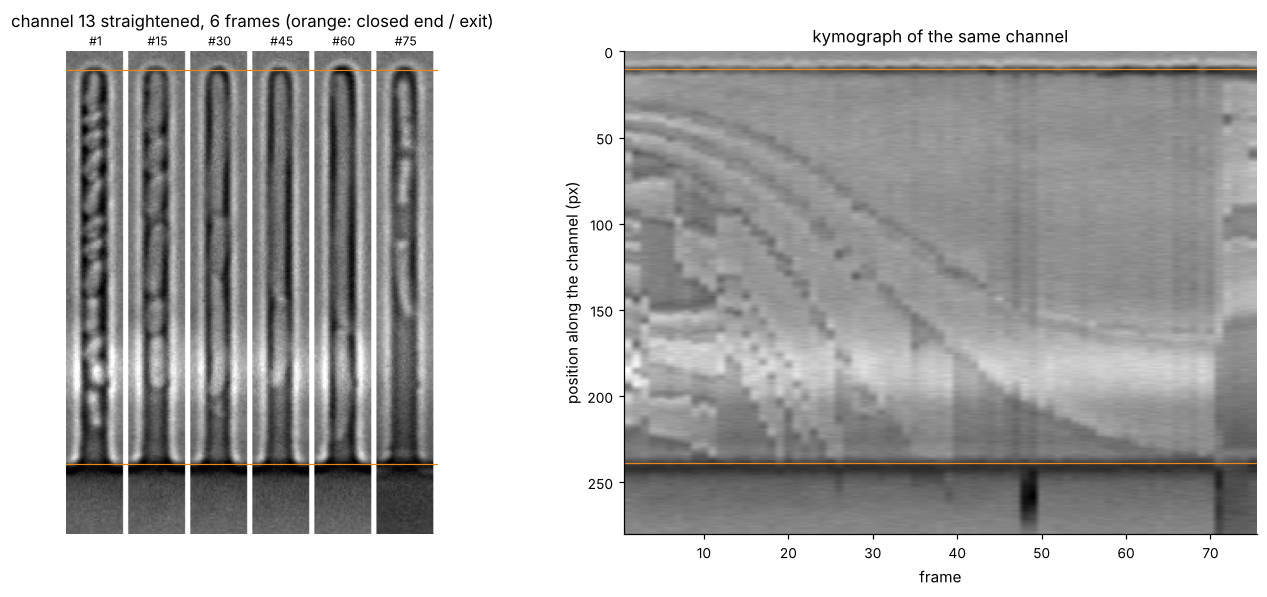

In [12]:
MARGEN_SUP, EXTRA_INF, ANCHO = kimogramas.MARGEN_SUP, kimogramas.EXTRA_INF, kimogramas.ANCHO
largo = int(np.ceil(canales.longitud_px.max())) + MARGEN_SUP + EXTRA_INF
canales['fila_fondo'] = MARGEN_SUP
canales['fila_salida'] = MARGEN_SUP + canales['longitud_px']

def recorte(stack, c, ancho, margen_sup, largo):
    p0 = np.array([c.x_sup, c.y_sup]); p1 = np.array([c.x_inf, c.y_inf])
    u = (p1 - p0) / np.linalg.norm(p1 - p0); n = np.array([-u[1], u[0]])
    s = np.arange(largo) - margen_sup; w = np.arange(ancho) - (ancho - 1) / 2
    pts = p0[None, None, :] + s[:, None, None] * u + w[None, :, None] * n
    fil, col = pts[..., 1].ravel(), pts[..., 0].ravel()
    return np.stack([map_coordinates(im.astype(np.float32), [fil, col], order=1, mode='nearest').reshape(largo, ancho) for im in stack])

CH = len(canales) // 2                       # channel to show
c = canales.iloc[CH]
ancho_crop = int(0.8 * periodo) | 1
frames = np.linspace(0, len(bf) - 1, 6).astype(int)
R = recorte(bf[frames], c, ancho_crop, MARGEN_SUP, largo)
K = kimogramas.kimograma(bf, c, ANCHO, MARGEN_SUP, EXTRA_INF, largo)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
mosaic = np.concatenate([np.pad(r / np.median(r), ((0, 0), (0, 3)), constant_values=np.nan) for r in R], axis=1)
ax[0].imshow(mosaic, cmap='gray', vmin=np.nanpercentile(mosaic, 0.5), vmax=np.nanpercentile(mosaic, 99.8), aspect='equal')
for k, t in enumerate(frames):
    ax[0].text(k * (ancho_crop + 3) + ancho_crop / 2, -4, f'#{t + 1}', ha='center', fontsize=8)
ax[0].axhline(c.fila_fondo, color=ORANGE, lw=0.8); ax[0].axhline(c.fila_salida, color=ORANGE, lw=0.8)
ax[0].set_title(f'channel {int(c.canal)} straightened, {len(frames)} frames (orange: closed end / exit)', pad=16); ax[0].axis('off')
ax[1].imshow(K, cmap='gray', aspect='auto', extent=[0.5, K.shape[1] + 0.5, K.shape[0], 0])
ax[1].axhline(c.fila_fondo, color=ORANGE, lw=0.8); ax[1].axhline(c.fila_salida, color=ORANGE, lw=0.8)
ax[1].set_xlabel('frame'); ax[1].set_ylabel('position along the channel (px)'); ax[1].set_title('kymograph of the same channel')
plt.tight_layout(); plt.show()

## Step 9 — Hard-coded values and what to change for another organism or chip

Everything above is controlled by a handful of numbers. They were tuned on one chip design and one magnification (E. coli, brightfield),
so they are the first suspects if detection fails on images that look different (for example another species, another pixel size, or phase contrast).

| Parameter | Value | Used in | If detection fails … |
|---|---|---|---|
| `PERIODO_MIN`, `PERIODO_MAX` | 20, 80 px | steps 2–3 | Must bracket the **channel spacing in pixels** of your images. Different magnification or chip → change first. |
| periodicity threshold | 0.4 | step 2 | Lower it if the band is not found (noisy / low-contrast comb). |
| wall-energy threshold | 30 % of max | step 2 | Lower if the band is too short; raise if it leaks into the feeding trench. |
| smoothing σ | period / 7 | steps 3, 5 | Must be small enough not to merge channel and wall. |
| minimum distance between channels | 0.6 × period | step 3 | |
| prominence filter | 30 % of typical | step 3 | Lower if real channels are rejected (weak contrast). |
| minima = **dark** channels | `find_peaks(-suave)` | steps 3, 5 | If channels are **brighter** than the walls (e.g. some phase-contrast settings), search maxima instead. |
| edge-channel contrast | 0.5 × typical | step 4 | |
| axis slope limit | 0.1 | step 5 | Raise if the chip is strongly rotated — or rotate the images first. |
| end / exit level | 0.5 × median wall energy | step 6 | |
| rigid-chip tolerance | 3 px (robust), 6 px (correction) | step 7 | |

Quick diagnostic if something fails: re-run steps 2, 3 and 6 on your images and look at the three plots — they show immediately
whether the band is found (step 2), whether the autocorrelation peak sits inside the search range (step 3) and whether the minima match the channels (step 3).

## Appendix — Two positions where steps 4 and 7 matter

On the position above nothing needed repairing (0 corrected ends, no extrapolated channel). Here we run the same function on two other
positions of the same experiment: one where the comb reaches the border of the field of view (extrapolated channels, step 4) and one where the
closed ends of some channels were wrong and had to be put back on the line (step 7).

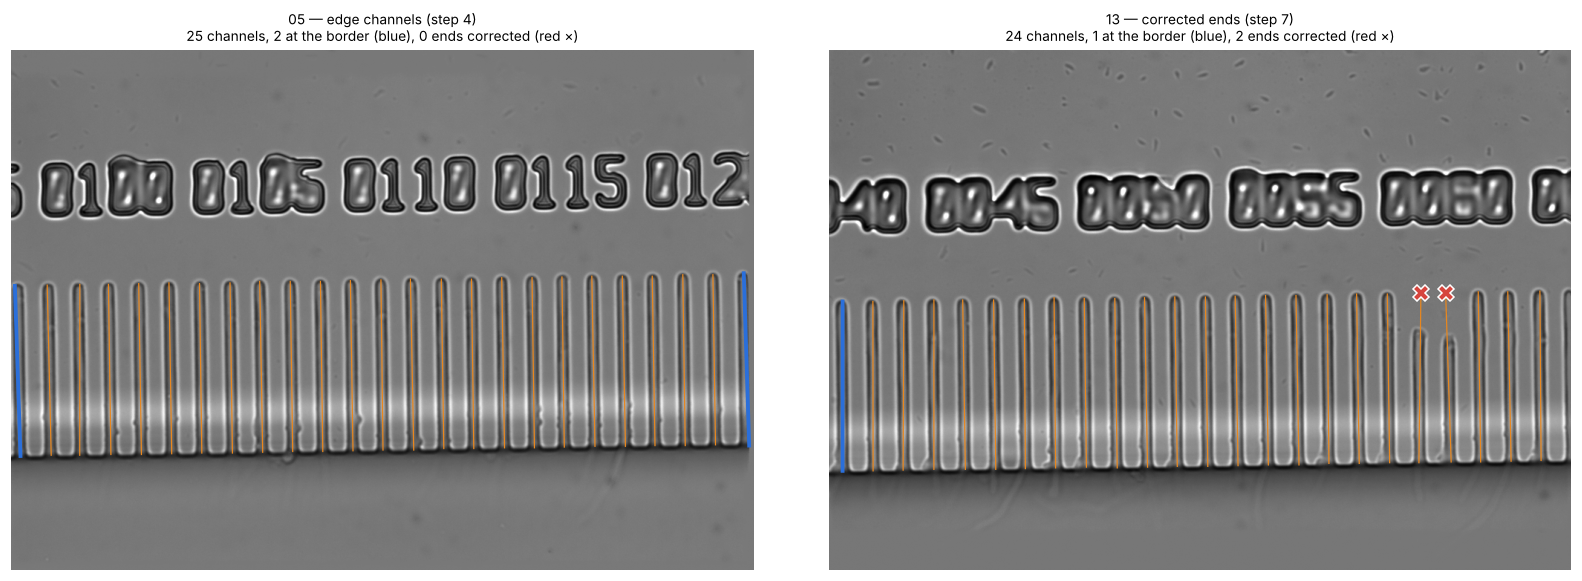

In [13]:
extras = [('05-02102026-BF.tif', 'edge channels (step 4)'), ('13-02102026-BF.tif', 'corrected ends (step 7)')]
extras = [(BASE / 'October/2/Stacks' / f, t) for f, t in extras if (BASE / 'October/2/Stacks' / f).exists()]
fig, ax = plt.subplots(1, max(len(extras), 1), figsize=(7.5 * max(len(extras), 1), 5.2), squeeze=False)
for a_, (ruta, titulo) in zip(ax[0], extras):
    with tifffile.TiffFile(ruta) as tif:
        st = tif.asarray()
    med = np.median(st, axis=0)
    cn, inf = kimogramas.detectar_canales(med)
    a_.imshow(med, cmap='gray')
    for _, c_ in cn.iterrows():
        a_.plot([c_.x_sup, c_.x_inf], [c_.y_sup, c_.y_inf], color=ORANGE, lw=0.8)
        if c_.al_borde:
            a_.plot([c_.x_sup, c_.x_inf], [c_.y_sup, c_.y_inf], color=BLUE, lw=2.5)
        if c_.corregido_sup:
            a_.plot(c_.x_sup, c_.y_sup, 'X', color=RED, ms=10, mec='white')
        if c_.corregido_inf:
            a_.plot(c_.x_inf, c_.y_inf, 'X', color=RED, ms=10, mec='white')
    a_.set_title(f'{ruta.name[:2]} — {titulo}\n{len(cn)} channels, {int(cn.al_borde.sum())} at the border (blue), '
                 f'{int(cn.corregido_sup.sum() + cn.corregido_inf.sum())} ends corrected (red ×)', fontsize=9)
    a_.axis('off')
plt.tight_layout(); plt.show()